# 04 · Régression (imputation de la sous-nutrition) et ACP

**Objectif 1.** Estimer le taux de sous-nutrition des 78 zones où il n'est pas mesuré, à partir de ce que
l'on sait de leur alimentation, avec un modèle évalué honnêtement (baseline, validation croisée).

**Objectif 2.** Résumer les indicateurs alimentaires en quelques axes (ACP) pour préparer le clustering.

Les valeurs imputées sont **toujours distinguées** des valeurs mesurées (colonne `Source_taux`).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import TransformedTargetRegressor
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.model_selection import RepeatedKFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = RACINE / "reports" / "figures"
df = pd.read_csv(RACINE / "data" / "global_fao_dataset.csv")
df["Log10_population"] = np.log10(df["Population_millions"])

## 1. Variables

| Rôle | Variable | Pourquoi |
|---|---|---|
| Cible | `Taux_sous_nutrition_pct` | ce que l'on veut imputer |
| Feature | `Kcal_total` | lien le plus fort au notebook 03 (ρ ≈ −0,89) |
| Feature | `Part_prot_animal_pct` | diversité du régime (ρ ≈ −0,53) |
| Feature | `Part_kcal_cereales_pct` | dépendance aux céréales (demandée par le brief) |
| Feature | `Log10_population` | taille du pays, en log car très asymétrique |

Aucune feature n'est calculée à partir de la cible : pas de fuite de données. Les scalers sont dans des
`Pipeline`, donc ajustés uniquement sur les données d'entraînement de chaque pli.

In [2]:
FEATURES = ["Kcal_total", "Part_prot_animal_pct", "Part_kcal_cereales_pct", "Log10_population"]
CIBLE = "Taux_sous_nutrition_pct"

connu = df.dropna(subset=[CIBLE])
X, y = connu[FEATURES], connu[CIBLE]
print(f"Entraînement possible sur {len(connu)} zones ; {df[CIBLE].isna().sum()} zones à imputer")
connu[FEATURES].corr().round(2)

Entraînement possible sur 96 zones ; 78 zones à imputer


,Kcal_total,Part_prot_animal_pct,Part_kcal_cereales_pct,Log10_population
Kcal_total,1.00,0.42,-0.13,0.13
Part_prot_animal_pct,0.42,1.00,-0.51,-0.15
Part_kcal_cereales_pct,-0.13,-0.51,1.00,0.17
Log10_population,0.13,-0.15,0.17,1.00


**Multicolinéarité.** Les features restent modérément corrélées entre elles. La régression Ridge, testée
ci-dessous, sert justement à stabiliser les coefficients dans ce cas.

## 2. Comparaison des modèles en validation croisée

Avec seulement 96 zones, un unique découpage train/test donne un score très dépendant du hasard (la
première version obtenait des R² de 0,33 à 0,74 selon le pli). On utilise donc une **validation croisée
5 plis répétée 10 fois** (50 évaluations), et on compare à une **baseline** qui prédit toujours la moyenne.

Le modèle « log-linéaire » apprend le logarithme du taux : il ne peut pas prédire de taux négatif et
reproduit la forme convexe observée au notebook 03.

In [3]:
modeles = {
    "Baseline (moyenne)": DummyRegressor(strategy="mean"),
    "Linéaire": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13))),
    "Log-linéaire": TransformedTargetRegressor(
        regressor=make_pipeline(StandardScaler(), LinearRegression()), func=np.log, inverse_func=np.exp),
    "Forêt aléatoire": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42),
}
cv = RepeatedKFold(n_splits=5, n_repeats=10, random_state=42)

lignes = []
for nom, modele in modeles.items():
    r = cross_validate(modele, X, y, cv=cv, scoring=["r2", "neg_root_mean_squared_error"])
    lignes.append({"modèle": nom,
                   "R² moyen": r["test_r2"].mean(), "R² écart-type": r["test_r2"].std(),
                   "RMSE moyenne (pts)": -r["test_neg_root_mean_squared_error"].mean()})
comparaison = pd.DataFrame(lignes).set_index("modèle").round(3)
comparaison

,R² moyen,R² écart-type,RMSE moyenne (pts)
modèle,,,
Baseline (moyenne),-0.09,0.12,11.83
Linéaire,0.65,0.16,6.48
Ridge,0.65,0.15,6.46
Log-linéaire,0.76,0.10,5.35
Forêt aléatoire,0.71,0.17,5.79


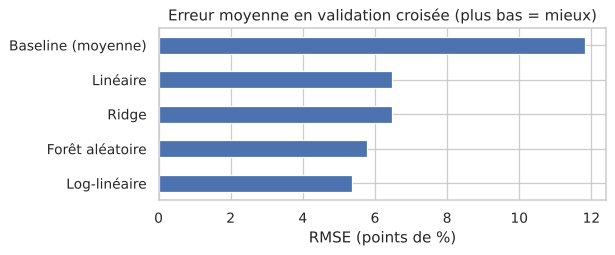

In [4]:
ax = comparaison["RMSE moyenne (pts)"].sort_values().plot.barh(figsize=(7, 3), color="#4C72B0")
ax.set(title="Erreur moyenne en validation croisée (plus bas = mieux)", xlabel="RMSE (points de %)", ylabel="")
plt.tight_layout(); plt.gcf().savefig(FIG / "comparaison_modeles.png", dpi=120)

**Choix.** Le modèle **log-linéaire** est le meilleur : R² ≈ 0,76 en moyenne, plus stable que les autres
(écart-type le plus faible), et une erreur moyenne d'environ 5 points de pourcentage, contre près de 12
pour la baseline. Il reste simple et interprétable, contrairement à la forêt aléatoire.

## 3. Contrôle sur un jeu de test mis de côté

Pour respecter la démarche du brief (split → fit → predict), on vérifie aussi le modèle retenu sur 20 %
des zones jamais vues à l'entraînement.

Test (20 zones) : R² = 0.78, RMSE = 6.7 pts  | baseline : R² = -0.06, RMSE = 14.5 pts


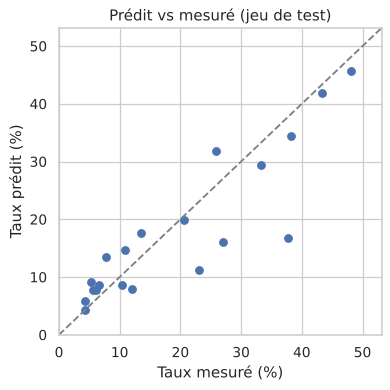

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
retenu = modeles["Log-linéaire"].fit(X_train, y_train)
pred = retenu.predict(X_test)
base = modeles["Baseline (moyenne)"].fit(X_train, y_train).predict(X_test)
print(f"Test ({len(y_test)} zones) : R² = {r2_score(y_test, pred):.2f}, RMSE = {root_mean_squared_error(y_test, pred):.1f} pts"
      f"  | baseline : R² = {r2_score(y_test, base):.2f}, RMSE = {root_mean_squared_error(y_test, base):.1f} pts")

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(y_test, pred, color="#4C72B0")
lim = [0, max(y_test.max(), pred.max()) + 5]
ax.plot(lim, lim, "--", color="grey"); ax.set(xlim=lim, ylim=lim, xlabel="Taux mesuré (%)", ylabel="Taux prédit (%)",
                                              title="Prédit vs mesuré (jeu de test)")
plt.tight_layout()

In [6]:
# Coefficients du modèle final (entraîné sur les 96 zones), sur le log du taux, variables standardisées
final = modeles["Log-linéaire"].fit(X, y)
coefs = pd.Series(final.regressor_[-1].coef_, index=FEATURES)
effet = ((np.exp(coefs) - 1) * 100).round(0)
pd.DataFrame({"coef (log, standardisé)": coefs.round(3), "effet d'un écart-type (%)": effet})

,"coef (log, standardisé)",effet d'un écart-type (%)
Kcal_total,-0.58,-44.00
Part_prot_animal_pct,-0.18,-17.00
Part_kcal_cereales_pct,-0.05,-5.00
Log10_population,-0.03,-3.00


**Lecture.** Une hausse d'un écart-type de la disponibilité calorique (≈ 360 kcal parmi les pays mesurés)
est associée à un taux de sous-nutrition **réduit d'environ 44 %**, à régime et population égaux. Un écart-type
de part de protéines animales en plus : environ −17 %. Céréales et population pèsent très peu : c'est la
quantité de calories disponibles qui porte l'essentiel de la prédiction.

## 4. Imputation

Règles :
- zones **« <0,1 million »** : la prédiction est plafonnée par la borne connue (`Taux_max_pct`) ;
- zones **NR / NV** : la prédiction est utilisée telle quelle, avec un avertissement si le pays est hors
  du domaine d'entraînement (disponibilité calorique plus haute que celle de tous les pays mesurés).

In [7]:
a_imputer = df[CIBLE].isna()
prediction = pd.Series(final.predict(df.loc[a_imputer, FEATURES]), index=df.index[a_imputer])
borne = df.loc[a_imputer, "Taux_max_pct"]
prediction = np.minimum(prediction, borne.fillna(np.inf))

df["Taux_final_pct"] = df[CIBLE]
df.loc[a_imputer, "Taux_final_pct"] = prediction
df["Source_taux"] = np.where(df[CIBLE].notna(), "mesuré", "imputé (modèle)")
df.loc[df["Sous_alim_borne"], "Source_taux"] = "imputé (plafonné par la borne FAO)"

hors_domaine = a_imputer & (df["Kcal_total"] > connu["Kcal_total"].max())
df["Hors_domaine_modele"] = hors_domaine
print(f"Zones imputées : {a_imputer.sum()} ; dont hors domaine (kcal > {connu['Kcal_total'].max():.0f}) : {hors_domaine.sum()}")
df.groupby("Source_taux")["Taux_final_pct"].describe()[["count", "mean", "min", "max"]].round(1)

Zones imputées : 78 ; dont hors domaine (kcal > 3518) : 8


,count,mean,min,max
Source_taux,,,,
imputé (modèle),55.00,4.70,1.60,24.20
imputé (plafonné par la borne FAO),23.00,8.40,4.10,22.00
mesuré,96.00,16.40,3.40,50.40


In [8]:
print("Les 10 taux imputés les plus élevés :")
df[a_imputer].nlargest(10, "Taux_final_pct")[["Zone", "Statut_sous_nutrition", "Kcal_total", "Taux_final_pct", "Taux_max_pct"]].round(1)

Les 10 taux imputés les plus élevés :


,Zone,Statut_sous_nutrition,Kcal_total,Taux_final_pct,Taux_max_pct
156,Tadjikistan,non disponible (NV),2 199.00,24.20,NaN
145,Sao Tomé-et-Principe,"< 0,1 million (borne)",2 398.00,22.00,51.80
73,Îles Salomon,"< 0,1 million (borne)",2 383.00,17.80,17.80
65,Grenade,non disponible (NV),2 442.00,14.20,NaN
28,Cabo Verde,"< 0,1 million (borne)",2 605.00,13.30,20.00
6,Antigua-et-Barbuda,non disponible (NV),2 416.00,13.30,NaN
142,Saint-Kitts-et-Nevis,non disponible (NV),2 491.00,12.80,NaN
141,Sainte-Lucie,non disponible (NV),2 589.00,11.00,NaN
18,Belize,"< 0,1 million (borne)",2 746.00,10.80,30.10
155,Suriname,"< 0,1 million (borne)",2 752.00,9.70,18.60


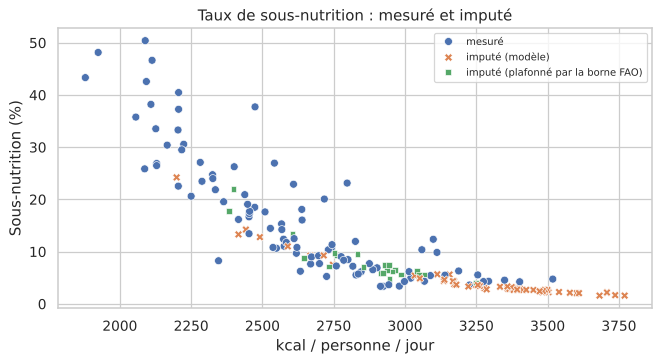

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
sns.scatterplot(data=df, x="Kcal_total", y="Taux_final_pct", hue="Source_taux", style="Source_taux", ax=ax, s=40)
ax.set(title="Taux de sous-nutrition : mesuré et imputé", xlabel="kcal / personne / jour", ylabel="Sous-nutrition (%)")
ax.legend(fontsize=8, title=None)
plt.tight_layout(); fig.savefig(FIG / "imputation.png", dpi=120)

**Lecture et limites.**

- Les 47 pays « non rapportés » (surtout riches) reçoivent des taux bas : médiane ≈ 3 %, de 1,6 %
  (États-Unis, Autriche) à 7,5 % (Japon). C'est cohérent avec leur absence des publications FAO, qui ne
  diffuse pas d'estimation quand la sous-nutrition est très faible.
- **Limite visible : le Japon.** Sa disponibilité calorique est modeste (2 747 kcal) pour un pays riche, donc
  le modèle lui attribue 7,5 %, sans doute trop. Le modèle ne connaît que l'alimentation, pas le revenu ni
  les inégalités.
- 8 pays dépassent la plus haute disponibilité calorique des pays mesurés (3 518 kcal) : pour eux le modèle
  **extrapole** (`Hors_domaine_modele`). Ces valeurs sont des ordres de grandeur, pas des mesures.
- Les plus fortes valeurs imputées concernent des pays sans donnée FAO et à disponibilité calorique faible
  (Tadjikistan 24 %, petites îles des Caraïbes) : ce sont elles qui mériteraient une vérification sur une
  autre source.
- Pour les totaux mondiaux, on n'additionne que les valeurs **mesurées**.

## 5. Analyse en composantes principales (ACP)

Variables : les 5 indicateurs de régime alimentaire, standardisés (unités différentes). On n'y met ni la
sous-nutrition (pour pouvoir la croiser ensuite avec les axes), ni la population (sans lien au régime).

In [10]:
VARS_ACP = ["Kcal_veg", "Kcal_anim", "Part_kcal_cereales_pct", "Prot_total_g", "Part_prot_animal_pct"]
X_acp = StandardScaler().fit_transform(df[VARS_ACP])
acp = PCA().fit(X_acp)
variance = pd.Series(acp.explained_variance_ratio_ * 100, index=[f"CP{i+1}" for i in range(len(VARS_ACP))])
print("Variance expliquée (%) :", variance.round(1).to_dict())
print(f"CP1 + CP2 = {variance.iloc[:2].sum():.1f} %")

charges = pd.DataFrame(acp.components_[:2].T, index=VARS_ACP, columns=["CP1", "CP2"]).round(2)
charges

Variance expliquée (%) : {'CP1': 63.4, 'CP2': 23.9, 'CP3': 9.5, 'CP4': 2.1, 'CP5': 1.0}
CP1 + CP2 = 87.3 %


,CP1,CP2
Kcal_veg,0.04,0.88
Kcal_anim,0.54,-0.02
Part_kcal_cereales_pct,-0.44,0.23
Prot_total_g,0.48,0.37
Part_prot_animal_pct,0.53,-0.19


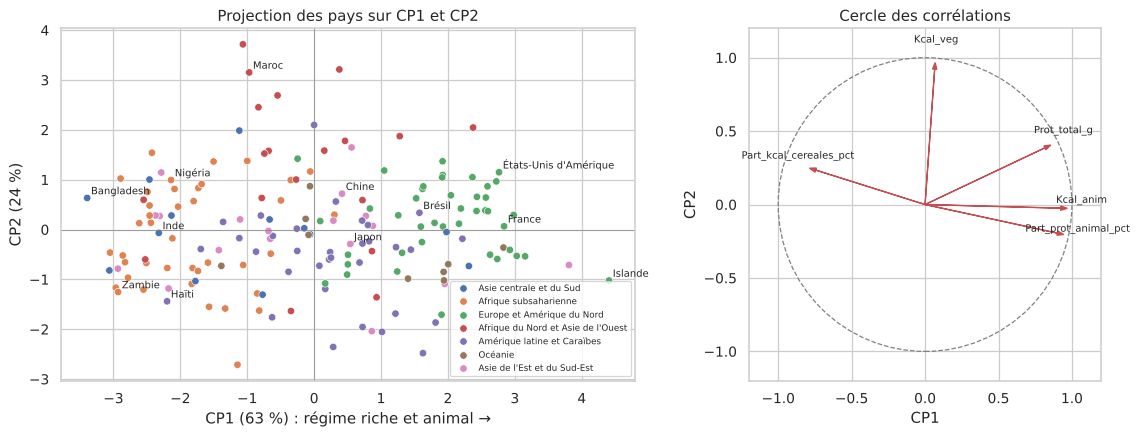

In [11]:
coords = acp.transform(X_acp)[:, :2]
df["CP1"], df["CP2"] = coords[:, 0], coords[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.5, 1]})
sns.scatterplot(data=df, x="CP1", y="CP2", hue="Region", ax=axes[0], s=35)
for _, r in df[df["Zone"].isin(["France", "États-Unis d'Amérique", "Inde", "Chine, continentale", "Nigéria",
                                "Haïti", "Zambie", "Bangladesh", "Maroc", "Brésil", "Japon", "Islande"])].iterrows():
    axes[0].annotate(r["Zone"].replace(", continentale", ""), (r["CP1"], r["CP2"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
axes[0].axhline(0, c="grey", lw=0.5); axes[0].axvline(0, c="grey", lw=0.5)
axes[0].set(title="Projection des pays sur CP1 et CP2",
            xlabel=f"CP1 ({variance.iloc[0]:.0f} %) : régime riche et animal →", ylabel=f"CP2 ({variance.iloc[1]:.0f} %)")
axes[0].legend(fontsize=7, title=None)
# Cercle des corrélations : corrélation de chaque variable avec CP1 et CP2
correl = pd.DataFrame(acp.components_[:2].T * np.sqrt(acp.explained_variance_[:2]), index=VARS_ACP, columns=["CP1", "CP2"])
for v in VARS_ACP:
    axes[1].arrow(0, 0, correl.loc[v, "CP1"], correl.loc[v, "CP2"], head_width=0.03, color="#C44E52", length_includes_head=True)
    axes[1].text(correl.loc[v, "CP1"] * 1.1, correl.loc[v, "CP2"] * 1.1 + 0.04, v, fontsize=8, ha="center")
axes[1].add_patch(plt.Circle((0, 0), 1, fill=False, ls="--", color="grey"))
axes[1].set(xlim=(-1.2, 1.2), ylim=(-1.2, 1.2), aspect="equal", title="Cercle des corrélations", xlabel="CP1", ylabel="CP2")
plt.tight_layout(); fig.savefig(FIG / "acp.png", dpi=120)

In [12]:
print("Corrélation de Spearman entre les axes et le taux de sous-nutrition mesuré :")
for cp in ["CP1", "CP2"]:
    d = df.dropna(subset=[CIBLE])
    from scipy.stats import spearmanr
    rho, p = spearmanr(d[cp], d[CIBLE])
    print(f"  {cp} : ρ = {rho:.2f} (p = {p:.1e})")

Corrélation de Spearman entre les axes et le taux de sous-nutrition mesuré :
  CP1 : ρ = -0.68 (p = 2.4e-14)
  CP2 : ρ = -0.55 (p = 6.9e-09)


**Interprétation, à partir des charges ci-dessus.**

- **CP1** oppose les régimes **riches en produits animaux et en protéines** (kcal animales, part de protéines
  animales et protéines totales fortement positives) aux régimes **dominés par les céréales** (part céréalière
  négative). C'est un axe « niveau de vie alimentaire » : pays européens et nord-américains à droite,
  Afrique subsaharienne et Asie du Sud à gauche. Il est fortement lié à la sous-nutrition (corrélation ci-dessus).
- **CP2** est porté surtout par les **kcal végétales** (charge 0,88) : il distingue, à niveau de vie égal,
  les pays où les calories végétales sont abondantes (Égypte, Turquie, Maghreb, en haut) de ceux où elles
  sont rares (République centrafricaine, Mongolie, en bas). Il est lui aussi négativement lié à la sous-nutrition.
- CP1 et CP2 résument **87 %** de l'information des 5 variables : ils serviront de base visuelle au
  clustering du notebook 05.

In [13]:
sortie = RACINE / "data" / "global_fao_dataset_impute.csv"
df.to_csv(sortie, index=False)
print(f"Exporté : {sortie.relative_to(RACINE)} ({len(df)} zones)")

Exporté : data/global_fao_dataset_impute.csv (174 zones)
